In [1]:
#Все необходимые библиотеки
import pandas as pd
import os
import numpy as np
import cv2
from PIL import Image
import copy

import torch
import torch.nn as nn
import torch.optim as optim
import torch as th

import torchvision
from torchvision import datasets, models
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import Dataset, DataLoader
from torchvision.io import read_image

from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight

import matplotlib.pyplot as plt
import matplotlib
%matplotlib inline

from skimage.io import imread
from torch.utils import data
from tqdm import tqdm

import glob
import re

import time

from sklearn.metrics import confusion_matrix
import seaborn as sns

from torchmetrics.classification import MulticlassSpecificity
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score
from sklearn.metrics import jaccard_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import matthews_corrcoef

C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#Класс для создания общего датасета с метаданными
class CombineDataset(Dataset):

    def __init__(self, frame, id_col, label_name, path_imgs, is_aug):
        
        self.frame = frame
        self.id_col = id_col
        self.label_name = label_name
        self.path_imgs = path_imgs
        self.is_aug = is_aug
        
        if self.is_aug == 1:
            self.aug = transforms.Compose([
                    transforms.Resize((img_size, img_size)),
                    transforms.RandomHorizontalFlip(),
                    transforms.RandomRotation(degrees=60),
                    transforms.ToTensor(),
                    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
                    ])
        else:
            self.aug = transforms.Compose([
                    transforms.Resize((img_size, img_size)),
                    transforms.ToTensor(),
                    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
                    ])
            
            

    def __len__(self):
        return (self.frame.shape[0])

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()
        
        img_name = self.frame[self.id_col].iloc[idx]
        img = os.path.join (self.path_imgs, img_name +'.jpg')

        image1 = Image.open(img)
        image = self.aug(image1)

        feats = [feat for feat in self.frame.columns if feat not in [self.label_name,self.id_col]]
        feats  = np.array(self.frame[feats].iloc[idx])
        feats = feats.tolist()
        feats = torch.FloatTensor(feats)

        label = np.array(self.frame[self.label_name].iloc[idx])
        label = torch.tensor(label, dtype=torch.long)
        
        name = self.frame[self.id_col].iloc[idx]

        return image, feats, label, name
    
class CombineDataset_cache(Dataset):

    def __init__(self, frame, id_col, label_name, path_imgs, use_cache = False):
        
        self.frame = frame
        self.id_col = id_col
        self.label_name = label_name
        self.path_imgs = path_imgs
        self.inputs_dtype = torch.float32
        
        self.transform = transforms.Compose([
                    transforms.Resize((img_size, img_size)),
                    transforms.ToTensor(),
                    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
                    ])
        
        self.use_cache = use_cache
        
        if self.use_cache:
            self.cached_data = []

            progressbar = tqdm(range(len(self.path_imgs)), desc='Caching')
            
            for i, img in zip(progressbar, self.path_imgs):
                img = Image.open(img)
                img= self.transform(img)                
                self.cached_data.append(img)
            
    def __len__(self):
        return (self.frame.shape[0])

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()
        
        img = self.cached_data[idx]

        feats = [feat for feat in self.frame.columns if feat not in [self.label_name,self.id_col]]
        feats  = np.array(self.frame[feats].iloc[idx])
        feats = feats.tolist()
        feats = torch.FloatTensor(feats)

        label = np.array(self.frame[self.label_name].iloc[idx])
        label = torch.tensor(label, dtype=torch.long)
        
        name = self.frame[self.id_col].iloc[idx]

        return img, feats, label, name
    
    
    # Определение процессора для обучения 
def get_default_device():
    if torch.cuda.is_available():
        
        return torch.device('cuda')
    else:
        return torch.device('cpu')

In [3]:
#Класс для выведения индексов для разделения базы изображений
class Sampler(object):
    def __init__(self, data_source):
        pass
    
    def __iter__(self):
        raise NotImplementedError
        
    def __len__(self):
        raise NotImplementedError
        
class StratifiedSampler(Sampler):
    
    def __init__(self, class_vector, z):
        self.n_splits = 1
        self.class_vector = class_vector
        self.test_size = z

    def gen_sample_array(self):
        try:
            from sklearn.model_selection import StratifiedShuffleSplit
        except:
             print('Ошибка распределения изображений')
        import numpy as np
        
        s = StratifiedShuffleSplit(n_splits=self.n_splits, test_size=self.test_size)
        X = th.randn(self.class_vector.size(0),2).numpy()
        y = self.class_vector.numpy()
        s.get_n_splits(X, y)

        train_index, test_index= next(s.split(X, y))
        return train_index, test_index

    def __iter__(self):
        return iter(self.gen_sample_array())

    def __len__(self):
        return len(self.class_vector)

In [4]:
def test(model, dataset, device):

    start_time_glob = time.time()
    model.to(device)
    model.eval()

    correct = 0
    total = 0
    time_outputs2 = 0

    with torch.no_grad():
        for i, data in enumerate(dataset):
            inputs, feats, labels, name = data
            inputs, feats, labels = inputs.to(device), feats.to(device), labels.to(device)

            start_time_outputs = time.time()

            outputs = model(inputs, feats)

            time_outputs = time.time()-start_time_outputs
            time_outputs2 += time_outputs

            _, predicted = torch.max(outputs.data, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total

    print('_' * 60)
    print ('       Время выхода с сети: {}'.format(time.strftime("%H:%M:%S", time.gmtime(time_outputs2))))
    print ('       Время выхода с сети в секундах: {:.6f}'.format(time_outputs2))

    time_glob = time.time()-start_time_glob
    print('_' * 60)
    print ('Время тестирования: {}'.format(time.strftime("%H:%M:%S", time.gmtime(time_glob))))
    print ('Время тестирования в секундах: {:.6f}\n'.format(time_glob))
    
    return accuracy

def test_NN(model, dataset):

    start_time_glob = time.time()
    model.eval()
    
    with torch.no_grad():
        for data in dataset:
            image, feats, label, name = data
            image, feats, label = image.to(device), feats.to(device), label.to(device)

            output = model(image, feats)

            pred = (torch.max(torch.exp(output), 1)[1]).cpu().data.numpy()

            predictions.extend(pred)

            label = label.cpu().data.numpy()
            actuals.extend(label)

    time_glob = time.time()-start_time_glob
    print('_' * 60)
    print ('Время тестирования: {}'.format(time.strftime("%H:%M:%S", time.gmtime(time_glob))))
    print ('Время тестирования в секундах: {:.6f}\n'.format(time_glob))
        
def test_metric():
    
    cm = confusion_matrix(actuals, predictions)
    FP = np.mean(cm.sum(axis=0) - np.diag(cm))  
    FN = np.mean(cm.sum(axis=1) - np.diag(cm))
    TP = np.mean(np.diag(cm))
    TN = np.mean(cm.sum() - (FP + FN + TP))

    Sensitivity = (TP/(TP+FN))
    Specificity = (TN/(TN+FP))
    Precision = (TP/(TP+FP))
    NPV = (TN/(TN+FN))
    PPV = (TP/(TP+FP))
    FNR = (FN/(FN+TP))
    FPR = (FP/(FP+TN))

    F1 = (2*TP)/((2*TP)+FP+FN) 

    recall_1 = recall_score(actuals, predictions, average='micro')
    recall_2 = recall_score(actuals, predictions, average='macro')
    

    precision_1 = precision_score(actuals, predictions, average='micro')
    precision_2 = precision_score(actuals, predictions, average='macro')


    f1_1 = f1_score(actuals, predictions, average='micro')
    f1_2 = f1_score(actuals, predictions, average='macro')
    
    jaccard_1 = jaccard_score(actuals, predictions, average='micro')
    jaccard_2 = jaccard_score(actuals, predictions, average='macro')

    accuracy_1 = accuracy_score(actuals, predictions)

    MCC = matthews_corrcoef(actuals, predictions)

    pre = torch.tensor(predictions)
    ac = torch.tensor(actuals)

    specificity1 = MulticlassSpecificity(average='macro', num_classes=10)
    s1 = specificity1(pre, ac)

    specificity2 = MulticlassSpecificity(average='micro', num_classes=10)
    s2 = specificity2(pre, ac)

    specificity3 = MulticlassSpecificity(average='weighted', num_classes=10)
    s3 = specificity3(pre, ac)

    specificity4 = MulticlassSpecificity(average='none', num_classes=10)
    s4 = specificity4(pre, ac)
    
    print('_' * 60)
    print('Accuracy score: %.2f' % (accuracy_1*100))
    print('Sensitivity: %.4f' % Sensitivity)
    print('Specificity: %.4f' % Specificity)
    print('Matthews corrcoef: %.4f' % MCC)
    print('F1: %.4f' % F1)
    print('NPV: %.4f' % NPV)
    print('PPV: %.4f' % PPV)
    print('FNR: %.4f' % FNR)
    print('FPR: %.4f' % FPR)
    
    print('_' * 60)
    print('Recall micro: %.4f' % recall_1)
    print('Recall macro: %.4f' % recall_2)
    print('Precision micro: %.4f' % precision_1)
    print('Precision macro: %.4f' % precision_2)
    print('F1 score micro: %.4f' % f1_1)
    print('F1 score macro: %.4f' % f1_2)
    
    print('Jaccard score micro: %.4f' % jaccard_1)
    print('Jaccard score macro: %.4f' % jaccard_2)
    print('Specificity macro: %.4f' % s1)
    print('Specificity weighted: %.4f' % s3)
    
    print('Specificity none - class vascular lesions (0): %.4f' % s4[0])
    print('Specificity none - class nevus (1): %.4f' % s4[1])
    print('Specificity none - class solar lentigo (2): %.4f' % s4[2])
    print('Specificity none - class dermatofibroma (3): %.4f' % s4[3])
    print('Specificity none - class seborrheic ketarosis (4): %.4f' % s4[4])
    print('Specificity none - class benign ketarosis (5): %.4f' % s4[5])
    print('Specificity none - class actinic keratosis (6): %.4f' % s4[6])
    print('Specificity none - class basal cell carcinoma (7): %.4f' % s4[7])
    print('Specificity none - class squamous cell carcinoma (8): %.4f' % s4[8])
    print('Specificity none - class melanoma (9): %.4f' % s4[9])

In [5]:
data_dir = "C:\\Users\\Ulyana\\...\\CLEAN DATASET\\"
metadata = pd.read_csv('C:\\Users\\Ulyana\\...\\MetaData2.csv')

numbers = re.compile(r'(\d+)')
def numericalSort(value):
    parts = numbers.split(value)
    parts[1::2] = map(int, parts[1::2])
    return parts

data_dir2 = sorted(glob.glob('C:\\Users\\Ulyana\\...\\CLEAN DATASET\\*.jpg'), key=numericalSort)

labels_cat = ['0. vascular lesions', '1. nevus', '2. solar lentigo', '3. dermatofibroma', '4. seborrheic ketarosis', '5. benign ketarosis', '6. actinic keratosis', '7. basal cell carcinoma', '8. squamous cell carcinoma', '9. melanoma']
labels_cat2 = ['vascular lesions', 'nevus', 'solar lentigo', 'dermatofibroma', 'seborrheic ketarosis', 'benign ketarosis', 'actinic keratosis', 'basal cell carcinoma', 'squamous cell carcinoma', 'melanoma']

img_size = 227
num_classes = 10
num_epochs = 10

#CPU или GPU
device = get_default_device()
device

device(type='cuda')

In [6]:
#Кодируем метаданные

metadata_age = metadata[['age']]
Age_grup = []

for i in metadata_age['age']:
    if i <= 44:
        Age_grup += ['young']
        #print('молодой')
    elif 45 <= i <= 59:
        Age_grup += ['middle']
        #print('средний')
    elif 60 <= i <= 74:
        Age_grup += ['elderly']
        #print('пожилой')
    elif 75 <= i:
        Age_grup += ['senile']
        #print('долгожители')
    else:
        Age_grup += ['error']
        #print('ошибка')
        
metadata['age'] = Age_grup

In [7]:
#Кодируем метаданные

encode_map_categor = {'0. vascular lesions': 0, '1. nevus': 1, '2. solar lentigo': 2, '3. dermatofibroma': 3, '4. seborrheic ketarosis': 4, '5. benign ketarosis': 5, '6. actinic keratosis': 6, '7. basal cell carcinoma': 7, '8. squamous cell carcinoma': 8, '9. melanoma': 9}

encode_map_age = {'young': 0, 'middle': 1, 'elderly': 2, 'senile': 3}
encode_map_sex = {'male': 0, 'female': 1}
encode_map_anatomloc = {'anterior torso': 0, 'head/neck': 1, 'lateral torso': 2, 'lower extremity': 3, 'oral/genital': 4, 'palms/soles': 5, 'posterior torso': 6, 'upper extremity': 7}

#encode_map_age = {'young': '0001', 'middle': '0010', 'elderly': '0100', 'senile': '1000'}
#encode_map_sex = {'male': '01', 'female': '10'}
#encode_map_anatomloc = {'anterior torso': '00000001', 'head/neck': '00000010', 'lateral torso': '00000100', 'lower extremity': '00001000', 'oral/genital': '00010000', 'palms/soles': '00100000', 'posterior torso': '01000000', 'upper extremity': '10000000'}

metadata['diagnosis'].replace(encode_map_categor, inplace=True)
metadata['age'].replace(encode_map_age, inplace=True)
metadata['sex'].replace(encode_map_sex, inplace=True)
metadata['anatomloc'].replace(encode_map_anatomloc, inplace=True)

metadata['diagnosis'] = np.array(metadata['diagnosis'], dtype=np.int32)
metadata['age'] = np.array(metadata['age'], dtype=np.int32)
metadata['sex'] = np.array(metadata['sex'], dtype=np.int32)
metadata['anatomloc'] = np.array(metadata['anatomloc'], dtype=np.int32)

C:\Users\Ulyana\AppData\Local\Temp\ipykernel_3928\1033980212.py:13: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  metadata['diagnosis'].replace(encode_map_categor, inplace=True)
C:\Users\Ulyana\AppData\Local\Temp\ipykernel_3928\1033980212.py:13: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  metadata

In [9]:
#Определяем индексы для разделения базы изображений

test_size = 0.2
valid_size = 0.25

data_label = metadata['diagnosis'].to_numpy()

ss = StratifiedSampler(torch.FloatTensor(data_label), test_size)
pre_train_indices, test_indices = ss.gen_sample_array()

train_label = np.delete(data_label, test_indices, None)
ss = StratifiedSampler(torch.FloatTensor(train_label), valid_size)
train_indices, val_indices = ss.gen_sample_array()

indices = {'train': pre_train_indices[train_indices],
           'val': pre_train_indices[val_indices],
           'test': test_indices
           }

train_indices = indices['train']
val_indices = indices['val']
test_indices = indices['test']

#Выводим индексы для разделения базы изображений

print("Размер тренировочной базы:", len(train_indices))
print("Размер валидационной базы:", len(val_indices))
print("Размер тестовой базы:", len(test_indices))

train_indices = torch.load('Parametr\\train_indices6.pt', weights_only=False)
val_indices = torch.load('Parametr\\val_indices6.pt', weights_only=False)
test_indices = torch.load('Parametr\\test_indices6.pt', weights_only=False)

Размер тренировочной базы: 25035
Размер валидационной базы: 8345
Размер тестовой базы: 8345


In [10]:
len_valset = len(val_indices)
len_trainset = len(train_indices)

In [11]:
#Функция для получения веса для каждой категории
def estimate_weights_mfb(label):
    class_weights = np.zeros_like(label, dtype=float)
    counts = np.zeros_like(label)
    for i,l in enumerate(label):
        m = metadata['diagnosis'].value_counts()
        counts[i] = m[i]
    counts = counts.astype(float)
    median_freq = np.median(counts)
    
    for i, label in enumerate(label):
        class_weights[i] = median_freq / counts[i]
    return class_weights

weight = estimate_weights_mfb(labels_cat)
weight = torch.FloatTensor(weight).to(device)

for i in range(len(labels_cat)):
    print(labels_cat[i],":", weight[i])

0. vascular lesions : tensor(3.8893, device='cuda:0')
1. nevus : tensor(0.0353, device='cuda:0')
2. solar lentigo : tensor(3.6444, device='cuda:0')
3. dermatofibroma : tensor(4., device='cuda:0')
4. seborrheic ketarosis : tensor(0.6721, device='cuda:0')
5. benign ketarosis : tensor(0.8954, device='cuda:0')
6. actinic keratosis : tensor(1.1323, device='cuda:0')
7. basal cell carcinoma : tensor(0.2900, device='cuda:0')
8. squamous cell carcinoma : tensor(1.5000, device='cuda:0')
9. melanoma : tensor(0.1758, device='cuda:0')


In [12]:
Data_set = CombineDataset_cache(metadata, 'name', 'diagnosis', data_dir2, use_cache = True)

Caching: 100%|██████████████████████████████████████████████████████████████████| 41725/41725 [02:22<00:00, 292.91it/s]


In [13]:
batch_size = 64

trainloader = torch.utils.data.DataLoader(Data_set, batch_size = batch_size, shuffle = False,  sampler = train_indices)
valloader = torch.utils.data.DataLoader(Data_set, batch_size = batch_size, shuffle = False,  sampler = val_indices)
testloader = torch.utils.data.DataLoader(Data_set, batch_size = batch_size, shuffle = False,  sampler = test_indices)

In [17]:
class MLP_Net(nn.Module):
    def __init__(self):
        super(MLP_Net, self).__init__()

        self.layer1 = nn.Sequential(
            nn.BatchNorm1d(num_features = 3),
            nn.Linear(3, 64, bias = True),
            nn.ReLU(inplace = False))

        self.layer2 = nn.Sequential(
            nn.BatchNorm1d(num_features = 64),
            nn.Linear(64, 32, bias = True),
            nn.ReLU(inplace = False))
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer1(inputs)
        x = self.layer2(x)
        x = self.layer_out(x)
        
        return x

MLP_Net = MLP_Net()

class CNN_Net(nn.Module):

   def __init__(self):
      super(CNN_Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.BatchNorm2d(num_features = 3),
         nn.Conv2d(3, 64, kernel_size = (3,3), stride = (1,1), padding = (1,1)),
         nn.ReLU(inplace = False),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode = False))
       
      self.layer2 = nn.Sequential(
         nn.Conv2d(64, 32, kernel_size = (3,3), stride = (1,1), padding = (1,1)),
         nn.ReLU(inplace = False),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode = False))
       
      self.layer3 = nn.Sequential(
         nn.Conv2d(32, 16, kernel_size = (3,3), stride = (1,1), padding = (1,1)),
         nn.ReLU(inplace = False),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode = False))
 
      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))
      self.fc1 = nn.Linear(16, 14)
      self.fc2 = nn.Linear(14, 12)
      self.fc3 = nn.Linear(12, num_classes)
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.layer3(x)
      x = self.pool1(x)
      x = x.view(x.size(0), -1)
       
      x = self.fc1(x)
      x = self.fc2(x)
      x = self.fc3(x)
       
      return x
       
CNN_Net = CNN_Net()
    
class Multimodal_Net(nn.Module):
    def __init__(self):
        super(Multimodal_Net, self).__init__()
        
        self.CNN_Net = CNN_Net
        self.MLP_Net = MLP_Net

        self.OUT_Net = nn.Sequential(
            nn.Linear(num_classes+num_classes, 32, bias = True),
            nn.Linear(32, 16, bias = True),
            nn.Linear(16, num_classes, bias = True))
                
    def forward(self, img , tab):
        
        img = self.CNN_Net(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.MLP_Net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.OUT_Net(x)
        
        return x


NET_light_64_32_16 = Multimodal_Net()

model_name = 'D:\\Python\\Distillation NN\\NET6\\NET_light_64_32_16.pt'
model_weights = torch.load(model_name, device)
NET_light_64_32_16.load_state_dict(model_weights)

NET_light_64_32_16 = NET_light_64_32_16.to(device)
NET_light_64_32_16

Multimodal_Net(
  (CNN_Net): CNN_Net(
    (layer1): Sequential(
      (0): BatchNorm2d(3, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (layer2): Sequential(
      (0): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (layer3): Sequential(
      (0): Conv2d(32, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (pool1): AdaptiveAvgPool2d(output_size=(1, 1))
    (fc1): Linear(in_features=16, out_features=14, bias=True)
    (fc2): Linear(in_features=14, out_features=12, bias=True)
    (fc3): Linear(in_features=12, out_features=10, bias=Tru

In [18]:
class MLP_Net(nn.Module):
    def __init__(self):
        super(MLP_Net, self).__init__()

        self.layer1 = nn.Sequential(
            nn.BatchNorm1d(num_features = 3),
            nn.Linear(3, 64, bias = True),
            nn.ReLU(inplace = False))

        self.layer2 = nn.Sequential(
            nn.BatchNorm1d(num_features = 64),
            nn.Linear(64, 32, bias = True),
            nn.ReLU(inplace = False))
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer1(inputs)
        x = self.layer2(x)
        x = self.layer_out(x)
        
        return x

MLP_Net = MLP_Net()

class CNN_Net(nn.Module):

   def __init__(self):
      super(CNN_Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.BatchNorm2d(num_features = 3),
         nn.Conv2d(3, 16, kernel_size = (3,3), stride = (1,1), padding = (1,1)),
         nn.ReLU(inplace = False),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode = False))

      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1)) 
      self.fc1 = nn.Linear(16, 14)
      self.fc2 = nn.Linear(14, 12)
      self.fc3 = nn.Linear(12, num_classes)
   
   def forward(self, x):
      
      x = self.layer1(x)
      x = self.pool1(x)       
      x = x.view(x.size(0), -1) 
      x = self.fc1(x)
      x = self.fc2(x)
      x = self.fc3(x)
       
      return x
       
CNN_Net = CNN_Net()
    
class Multimodal_Net(nn.Module):
    def __init__(self):
        super(Multimodal_Net, self).__init__()
        
        self.CNN_Net = CNN_Net
        self.MLP_Net = MLP_Net

        self.OUT_Net = nn.Sequential(
            nn.Linear(num_classes+num_classes, 32, bias = True),
            nn.Linear(32, 16, bias = True),
            nn.Linear(16, num_classes, bias = True))
                
    def forward(self, img , tab):
        
        img = self.CNN_Net(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.MLP_Net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.OUT_Net(x)
        
        return x


NET_light_16 = Multimodal_Net()

model_name = 'D:\\Python\\Distillation NN\\NET6\\NET_light_16.pt'
model_weights = torch.load(model_name, device)
NET_light_16.load_state_dict(model_weights)

NET_light_16 = NET_light_16.to(device)
NET_light_16

Multimodal_Net(
  (CNN_Net): CNN_Net(
    (layer1): Sequential(
      (0): BatchNorm2d(3, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (pool1): AdaptiveAvgPool2d(output_size=(1, 1))
    (fc1): Linear(in_features=16, out_features=14, bias=True)
    (fc2): Linear(in_features=14, out_features=12, bias=True)
    (fc3): Linear(in_features=12, out_features=10, bias=True)
  )
  (MLP_Net): MLP_Net(
    (layer1): Sequential(
      (0): BatchNorm1d(3, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (1): Linear(in_features=3, out_features=64, bias=True)
      (2): ReLU()
    )
    (layer2): Sequential(
      (0): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (1): Linear(in_features=64, out_features=32, bias=True)
      (2): ReLU()

In [19]:
class MLP_Net(nn.Module):
    def __init__(self):
        super(MLP_Net, self).__init__()

        self.layer1 = nn.Sequential(
            nn.BatchNorm1d(num_features = 3),
            nn.Linear(3, 64, bias = True),
            nn.ReLU(inplace = False))

        self.layer2 = nn.Sequential(
            nn.BatchNorm1d(num_features = 64),
            nn.Linear(64, 32, bias = True),
            nn.ReLU(inplace = False))
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer1(inputs)
        x = self.layer2(x)
        x = self.layer_out(x)
        
        return x

MLP_Net = MLP_Net()

class CNN_Net(nn.Module):

   def __init__(self):
      super(CNN_Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.BatchNorm2d(num_features = 3),          
         nn.Conv2d(3, 128, kernel_size = (3,3), stride = (1,1), padding = (1,1)),
         nn.ReLU(inplace = False),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode = False))
       
      self.layer2 = nn.Sequential(
         nn.Conv2d(128, 64, kernel_size = (3,3), stride = (1,1), padding = (1,1)),
         nn.ReLU(inplace = False),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode = False))
       
      self.layer3 = nn.Sequential(
         nn.Conv2d(64, 32, kernel_size = (3,3), stride = (1,1), padding = (1,1)),
         nn.ReLU(inplace = False),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode = False))

      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))       
      self.fc1 = nn.Linear(32, 16)
      self.fc2 = nn.Linear(16, 12)
      self.fc3 = nn.Linear(12, num_classes)
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.layer3(x)
      x = self.pool1(x)       
      x = x.view(x.size(0), -1)
       
      x = self.fc1(x)
      x = self.fc2(x)
      x = self.fc3(x)
       
      return x
       
CNN_Net = CNN_Net()
    
class Multimodal_Net(nn.Module):
    def __init__(self):
        super(Multimodal_Net, self).__init__()
        
        self.CNN_Net = CNN_Net
        self.MLP_Net = MLP_Net

        self.OUT_Net = nn.Sequential(
            nn.Linear(num_classes+num_classes, 32, bias = True),
            nn.Linear(32, 16, bias = True),
            nn.Linear(16, num_classes, bias = True))
                
    def forward(self, img , tab):
        
        img = self.CNN_Net(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.MLP_Net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.OUT_Net(x)
        
        return x


NET_light_128_64_32 = Multimodal_Net()

model_name = 'D:\\Python\\Distillation NN\\NET6\\NET_light_128_64_32.pt'
model_weights = torch.load(model_name, device)
NET_light_128_64_32.load_state_dict(model_weights)

NET_light_128_64_32 = NET_light_128_64_32.to(device)
NET_light_128_64_32

Multimodal_Net(
  (CNN_Net): CNN_Net(
    (layer1): Sequential(
      (0): BatchNorm2d(3, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (1): Conv2d(3, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (layer2): Sequential(
      (0): Conv2d(128, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (layer3): Sequential(
      (0): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (pool1): AdaptiveAvgPool2d(output_size=(1, 1))
    (fc1): Linear(in_features=32, out_features=16, bias=True)
    (fc2): Linear(in_features=16, out_features=12, bias=True)
    (fc3): Linear(in_features=12, out_features=10, bias=T

In [20]:
class MLP_Net(nn.Module):
    def __init__(self):
        super(MLP_Net, self).__init__()

        self.layer1 = nn.Sequential(
            nn.BatchNorm1d(num_features = 3),
            nn.Linear(3, 64, bias = True),
            nn.ReLU(inplace = False))

        self.layer2 = nn.Sequential(
            nn.BatchNorm1d(num_features = 64),
            nn.Linear(64, 32, bias = True),
            nn.ReLU(inplace = False))
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer1(inputs)
        x = self.layer2(x)
        x = self.layer_out(x)
        
        return x

MLP_Net = MLP_Net()

class CNN_Net(nn.Module):

   def __init__(self):
      super(CNN_Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.BatchNorm2d(num_features = 3),          
         nn.Conv2d(3, 32, kernel_size = (3,3), stride = (1,1), padding = (1,1)),
         nn.ReLU(inplace = False),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode = False))

      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))         
      self.fc1 = nn.Linear(32, 16)
      self.fc2 = nn.Linear(16, 12)
      self.fc3 = nn.Linear(12, num_classes)
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.pool1(x)       
      x = x.view(x.size(0), -1)
       
      x = self.fc1(x)
      x = self.fc2(x)
      x = self.fc3(x)
       
      return x
       
CNN_Net = CNN_Net()
    
class Multimodal_Net(nn.Module):
    def __init__(self):
        super(Multimodal_Net, self).__init__()
        
        self.CNN_Net = CNN_Net
        self.MLP_Net = MLP_Net

        self.OUT_Net = nn.Sequential(
            nn.Linear(num_classes+num_classes, 32, bias = True),
            nn.Linear(32, 16, bias = True),
            nn.Linear(16, num_classes, bias = True))
                
    def forward(self, img , tab):
        
        img = self.CNN_Net(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.MLP_Net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.OUT_Net(x)
        
        return x

NET_light_32 = Multimodal_Net()

model_name = 'D:\\Python\\Distillation NN\\NET6\\NET_light_32.pt'
model_weights = torch.load(model_name, device)
NET_light_32.load_state_dict(model_weights)

NET_light_32 = NET_light_32.to(device)
NET_light_32

Multimodal_Net(
  (CNN_Net): CNN_Net(
    (layer1): Sequential(
      (0): BatchNorm2d(3, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (pool1): AdaptiveAvgPool2d(output_size=(1, 1))
    (fc1): Linear(in_features=32, out_features=16, bias=True)
    (fc2): Linear(in_features=16, out_features=12, bias=True)
    (fc3): Linear(in_features=12, out_features=10, bias=True)
  )
  (MLP_Net): MLP_Net(
    (layer1): Sequential(
      (0): BatchNorm1d(3, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (1): Linear(in_features=3, out_features=64, bias=True)
      (2): ReLU()
    )
    (layer2): Sequential(
      (0): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (1): Linear(in_features=64, out_features=32, bias=True)
      (2): ReLU()

In [21]:
class MLP_Net(nn.Module):
    def __init__(self):
        super(MLP_Net, self).__init__()

        self.layer1 = nn.Sequential(
            nn.BatchNorm1d(num_features = 3),
            nn.Linear(3, 64, bias = True),
            nn.ReLU(inplace = False))

        self.layer2 = nn.Sequential(
            nn.BatchNorm1d(num_features = 64),
            nn.Linear(64, 32, bias = True),
            nn.ReLU(inplace = False))
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer1(inputs)
        x = self.layer2(x)
        x = self.layer_out(x)
        
        return x

MLP_Net = MLP_Net()

class CNN_Net(nn.Module):

   def __init__(self):
      super(CNN_Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.BatchNorm2d(num_features = 3),          
         nn.Conv2d(3, 256, kernel_size = (3,3), stride = (1,1), padding = (1,1)),
         nn.ReLU(inplace = False),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode = False))
       
      self.layer2 = nn.Sequential(
         nn.Conv2d(256, 128, kernel_size = (3,3), stride = (1,1), padding = (1,1)),
         nn.ReLU(inplace = False),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode = False))
       
      self.layer3 = nn.Sequential(
         nn.Conv2d(128, 64, kernel_size = (3,3), stride = (1,1), padding = (1,1)),
         nn.ReLU(inplace = False),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode = False))

      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))         
      self.fc1 = nn.Linear(64, 32)
      self.fc2 = nn.Linear(32, 16)
      self.fc3 = nn.Linear(16, num_classes)
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.layer3(x)
      x = self.pool1(x)           
      x = x.view(x.size(0), -1)
       
      x = self.fc1(x)
      x = self.fc2(x)
      x = self.fc3(x)
       
      return x
       
CNN_Net = CNN_Net()
    
class Multimodal_Net(nn.Module):
    def __init__(self):
        super(Multimodal_Net, self).__init__()
        
        self.CNN_Net = CNN_Net
        self.MLP_Net = MLP_Net

        self.OUT_Net = nn.Sequential(
            nn.Linear(num_classes+num_classes, 32, bias = True),
            nn.Linear(32, 16, bias = True),
            nn.Linear(16, num_classes, bias = True))
                
    def forward(self, img , tab):
        
        img = self.CNN_Net(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.MLP_Net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.OUT_Net(x)
        
        return x


NET_light_256_128_64 = Multimodal_Net()

model_name = 'D:\\Python\\Distillation NN\\NET6\\NET_light_256_128_64.pt'
model_weights = torch.load(model_name, device)
NET_light_256_128_64.load_state_dict(model_weights)

NET_light_256_128_64 = NET_light_256_128_64.to(device)
NET_light_256_128_64

Multimodal_Net(
  (CNN_Net): CNN_Net(
    (layer1): Sequential(
      (0): BatchNorm2d(3, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (1): Conv2d(3, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (layer2): Sequential(
      (0): Conv2d(256, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (layer3): Sequential(
      (0): Conv2d(128, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (pool1): AdaptiveAvgPool2d(output_size=(1, 1))
    (fc1): Linear(in_features=64, out_features=32, bias=True)
    (fc2): Linear(in_features=32, out_features=16, bias=True)
    (fc3): Linear(in_features=16, out_features=10, bias

In [22]:
class MLP_Net(nn.Module):
    def __init__(self):
        super(MLP_Net, self).__init__()

        self.layer1 = nn.Sequential(
            nn.BatchNorm1d(num_features = 3),
            nn.Linear(3, 64, bias = True),
            nn.ReLU(inplace = False))

        self.layer2 = nn.Sequential(
            nn.BatchNorm1d(num_features = 64),
            nn.Linear(64, 32, bias = True),
            nn.ReLU(inplace = False))
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer1(inputs)
        x = self.layer2(x)
        x = self.layer_out(x)
        
        return x

MLP_Net = MLP_Net()

class CNN_Net(nn.Module):

   def __init__(self):
      super(CNN_Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.BatchNorm2d(num_features = 3),          
         nn.Conv2d(3, 64, kernel_size = (3,3), stride = (1,1), padding = (1,1)),
         nn.ReLU(inplace = False),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode = False))

      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))        
      self.fc1 = nn.Linear(64, 32)
      self.fc2 = nn.Linear(32, 16)
      self.fc3 = nn.Linear(16, num_classes)
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.pool1(x)
      x = x.view(x.size(0), -1)
       
      x = self.fc1(x)
      x = self.fc2(x)
      x = self.fc3(x)
       
      return x
       
CNN_Net = CNN_Net()
    
class Multimodal_Net(nn.Module):
    def __init__(self):
        super(Multimodal_Net, self).__init__()
        
        self.CNN_Net = CNN_Net
        self.MLP_Net = MLP_Net

        self.OUT_Net = nn.Sequential(
            nn.Linear(num_classes+num_classes, 32, bias = True),
            nn.Linear(32, 16, bias = True),
            nn.Linear(16, num_classes, bias = True))
                
    def forward(self, img , tab):
        
        img = self.CNN_Net(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.MLP_Net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.OUT_Net(x)
        
        return x


NET_light_64 = Multimodal_Net()

model_name = 'D:\\Python\\Distillation NN\\NET6\\NET_light_64.pt'
model_weights = torch.load(model_name, device)
NET_light_64.load_state_dict(model_weights)

NET_light_64 = NET_light_64.to(device)
NET_light_64

Multimodal_Net(
  (CNN_Net): CNN_Net(
    (layer1): Sequential(
      (0): BatchNorm2d(3, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (pool1): AdaptiveAvgPool2d(output_size=(1, 1))
    (fc1): Linear(in_features=64, out_features=32, bias=True)
    (fc2): Linear(in_features=32, out_features=16, bias=True)
    (fc3): Linear(in_features=16, out_features=10, bias=True)
  )
  (MLP_Net): MLP_Net(
    (layer1): Sequential(
      (0): BatchNorm1d(3, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (1): Linear(in_features=3, out_features=64, bias=True)
      (2): ReLU()
    )
    (layer2): Sequential(
      (0): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (1): Linear(in_features=64, out_features=32, bias=True)
      (2): ReLU()

In [23]:
class MLP_Net(nn.Module):
    def __init__(self):
        super(MLP_Net, self).__init__()

        self.layer1 = nn.Sequential(
            nn.BatchNorm1d(num_features = 3),
            nn.Linear(3, 64, bias = True),
            nn.ReLU(inplace = False))

        self.layer2 = nn.Sequential(
            nn.BatchNorm1d(num_features = 64),
            nn.Linear(64, 32, bias = True),
            nn.ReLU(inplace = False))
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer1(inputs)
        x = self.layer2(x)
        x = self.layer_out(x)
        
        return x

MLP_Net = MLP_Net()

class CNN_Net(nn.Module):

   def __init__(self):
      super(CNN_Net, self).__init__()
      
      self.layer1 = nn.Sequential(
         nn.BatchNorm2d(num_features = 3),         
         nn.Conv2d(3, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=False),
         nn.Conv2d(64, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=False),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.layer2 = nn.Sequential(
         nn.Conv2d(64, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=False),
         nn.Conv2d(128, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=False),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))
      self.fc1 = nn.Linear(128, 32)
      self.fc2 = nn.Linear(32, num_classes)
      self.dropout_rate = 0.5
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.pool1(x)
      x = x.view(x.size(0), -1)
      x = self.fc1(x)
      x = self.fc2(x)
       
      return x
       
CNN_Net = CNN_Net()
    
class Multimodal_Net(nn.Module):
    def __init__(self):
        super(Multimodal_Net, self).__init__()
        
        self.CNN_Net = CNN_Net
        self.MLP_Net = MLP_Net

        self.OUT_Net = nn.Sequential(
            nn.Linear(num_classes+num_classes, 32, bias = True),
            nn.Linear(32, 16, bias = True),
            nn.Linear(16, num_classes, bias = True))
                
    def forward(self, img , tab):
        
        img = self.CNN_Net(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.MLP_Net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.OUT_Net(x)
        
        return x

NET_light_NACH = Multimodal_Net()

model_name = 'D:\\Python\\Distillation NN\\NET6\\NET_light_NACH.pt'
model_weights = torch.load(model_name, device)
NET_light_NACH.load_state_dict(model_weights)

NET_light_NACH = NET_light_NACH.to(device)
NET_light_NACH

Multimodal_Net(
  (CNN_Net): CNN_Net(
    (layer1): Sequential(
      (0): BatchNorm2d(3, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (2): ReLU()
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): ReLU()
      (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (layer2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU()
      (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (pool1): AdaptiveAvgPool2d(output_size=(1, 1))
    (fc1): Linear(in_features=128, out_features=32, bias=True)
    (fc2): Linear(in_features=32, out_features=10, bias=True)
  )
  (MLP_Net): MLP_Net(
    (layer1): Sequential(
      (0): BatchNorm1d(3, 

____________________________________________________________
Время тестирования: 00:00:07
Время тестирования в секундах: 7.222280



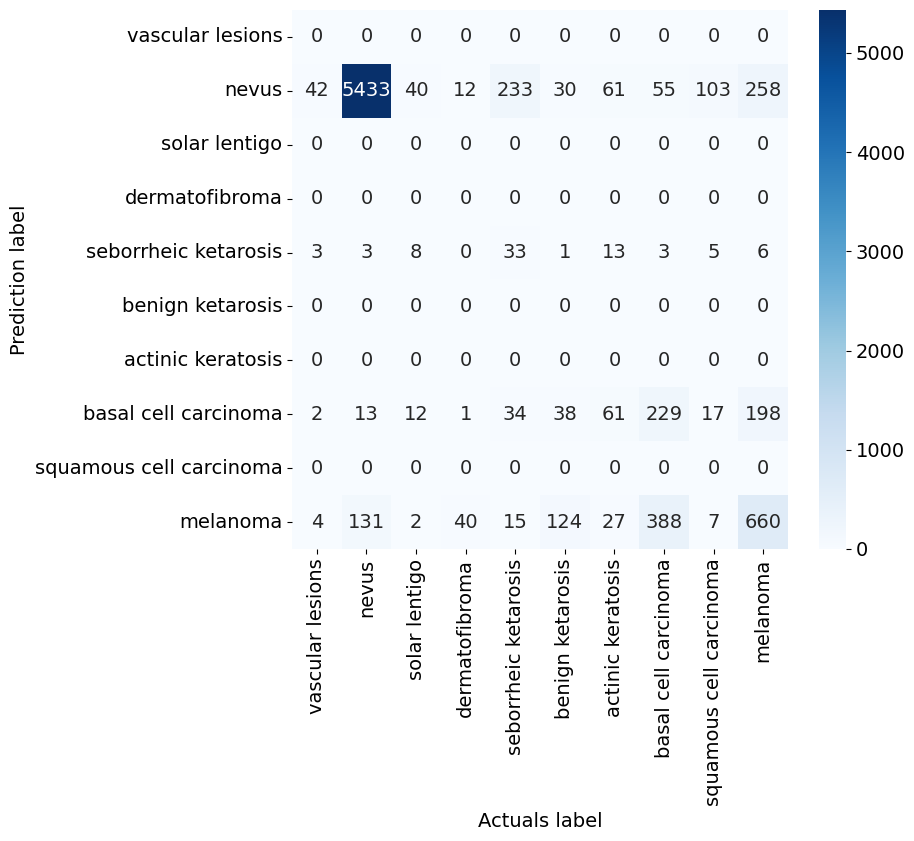

____________________________________________________________
Accuracy score: 76.15
Sensitivity: 0.7615
Specificity: 0.9735
Matthews corrcoef: 0.5014
F1: 0.7615
NPV: 0.9735
PPV: 0.7615
FNR: 0.2385
FPR: 0.0265
____________________________________________________________
Recall micro: 0.7615
Recall macro: 0.2006
Precision micro: 0.7615
Precision macro: 0.2158
F1 score micro: 0.7615
F1 score macro: 0.1968
Jaccard score micro: 0.6149
Jaccard score macro: 0.1512
Specificity macro: 0.9542
Specificity weighted: 0.7804
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.6984
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9948
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 1.0000
Specificity none - class basal cell carcinoma (7): 0.9510
Specificity none - class squamous cell carcinoma (8): 1.000

C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [25]:
actuals = []
predictions = []

test_NN(NET_light_64_32_16, testloader)

#torch.save(actuals, 'NET_light_64_32_16\\actuals2.pt')
#torch.save(predictions, 'NET_light_64_32_16\\predictions2.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

#torch.save(matrix, 'NET_light_64_32_16\\matrix2.pt')

test_metric()

____________________________________________________________
Время тестирования: 00:00:05
Время тестирования в секундах: 5.926765



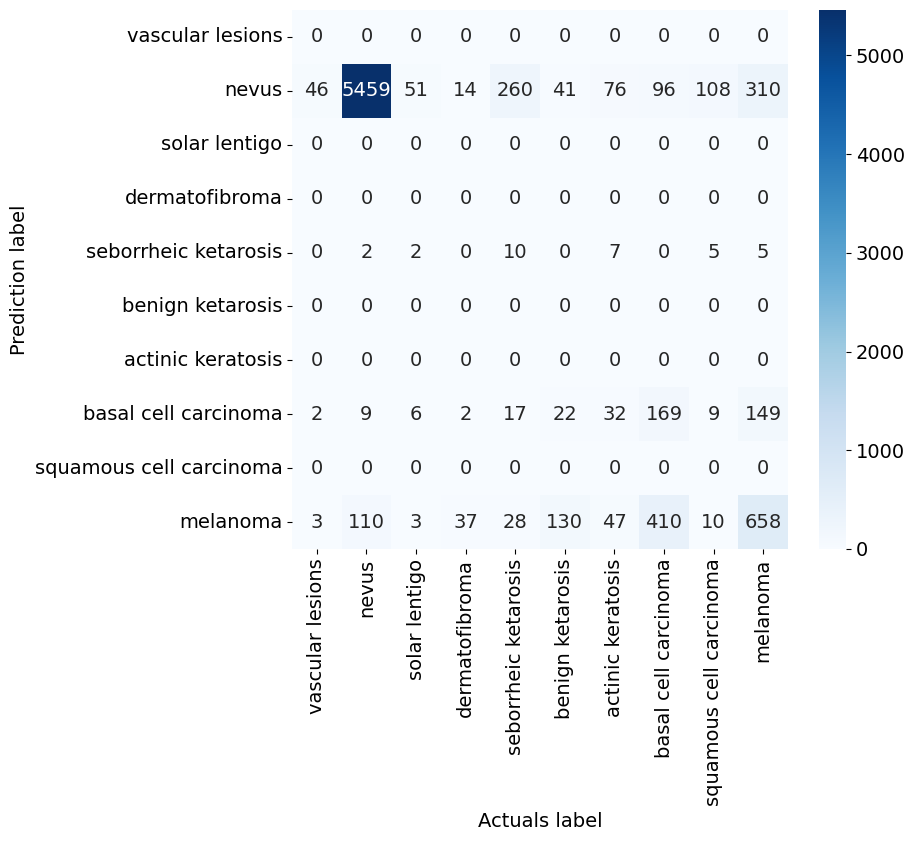

____________________________________________________________
Accuracy score: 75.45
Sensitivity: 0.7545
Specificity: 0.9727
Matthews corrcoef: 0.4760
F1: 0.7545
NPV: 0.9727
PPV: 0.7545
FNR: 0.2455
FPR: 0.0273
____________________________________________________________
Recall micro: 0.7545
Recall macro: 0.1847
Precision micro: 0.7545
Precision macro: 0.2031
F1 score micro: 0.7545
F1 score macro: 0.1789
Jaccard score micro: 0.6057
Jaccard score macro: 0.1389
Specificity macro: 0.9495
Specificity weighted: 0.7405
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.6376
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9974
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 1.0000
Specificity none - class basal cell carcinoma (7): 0.9677
Specificity none - class squamous cell carcinoma (8): 1.000

C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [27]:
actuals = []
predictions = []

test_NN(NET_light_16, testloader)

#torch.save(actuals, 'NET_light_16\\actuals.pt')
#torch.save(predictions, 'NET_light_16\\predictions.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

#torch.save(matrix, 'NET_light_16\\matrix.pt')

test_metric()

____________________________________________________________
Время тестирования: 00:00:08
Время тестирования в секундах: 8.159347



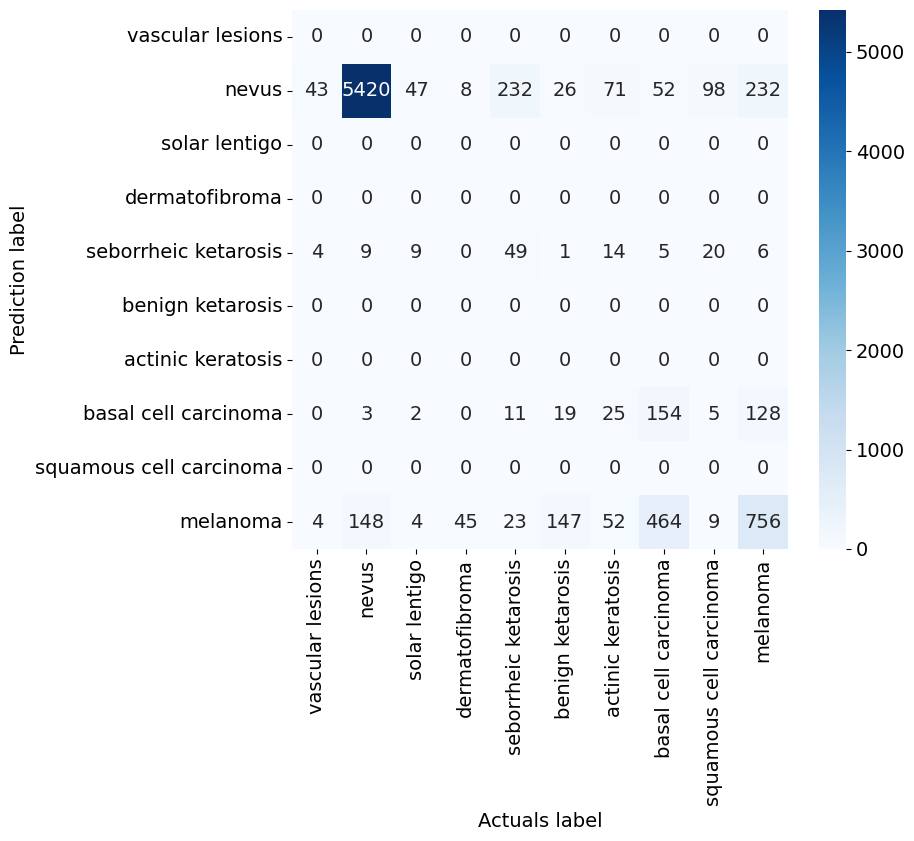

____________________________________________________________
Accuracy score: 76.44
Sensitivity: 0.7644
Specificity: 0.9738
Matthews corrcoef: 0.5110
F1: 0.7644
NPV: 0.9738
PPV: 0.7644
FNR: 0.2356
FPR: 0.0262
____________________________________________________________
Recall micro: 0.7644
Recall macro: 0.2029
Precision micro: 0.7644
Precision macro: 0.2190
F1 score micro: 0.7644
F1 score macro: 0.1991
Jaccard score micro: 0.6187
Jaccard score macro: 0.1528
Specificity macro: 0.9550
Specificity weighted: 0.7853
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.7074
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9915
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 1.0000
Specificity none - class basal cell carcinoma (7): 0.9748
Specificity none - class squamous cell carcinoma (8): 1.000

C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [29]:
actuals = []
predictions = []

test_NN(NET_light_128_64_32, testloader)

#torch.save(actuals, 'NET_light_128_64_32\\actuals.pt')
#torch.save(predictions, 'NET_light_128_64_32\\predictions.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

#torch.save(matrix, 'NET_light_128_64_32\\matrix.pt')

test_metric()

____________________________________________________________
Время тестирования: 00:00:05
Время тестирования в секундах: 5.446505



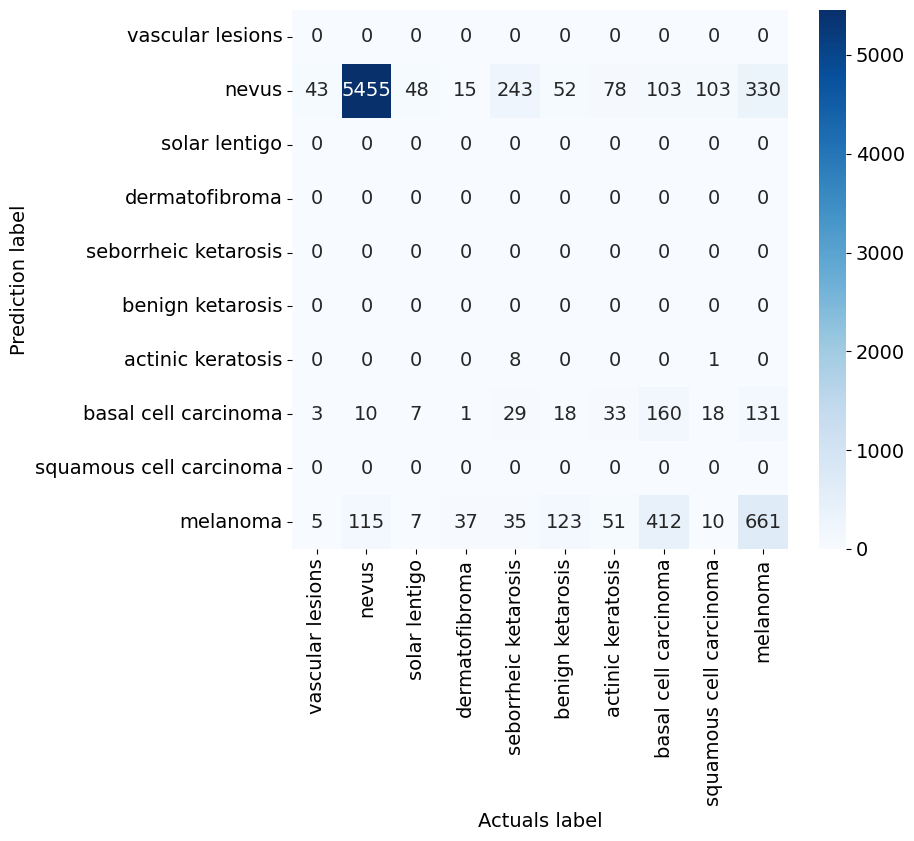

____________________________________________________________
Accuracy score: 75.21
Sensitivity: 0.7521
Specificity: 0.9725
Matthews corrcoef: 0.4701
F1: 0.7521
NPV: 0.9725
PPV: 0.7521
FNR: 0.2479
FPR: 0.0275
____________________________________________________________
Recall micro: 0.7521
Recall macro: 0.1804
Precision micro: 0.7521
Precision macro: 0.1687
F1 score micro: 0.7521
F1 score macro: 0.1713
Jaccard score micro: 0.6027
Jaccard score macro: 0.1345
Specificity macro: 0.9489
Specificity weighted: 0.7371
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.6329
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 1.0000
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 0.9989
Specificity none - class basal cell carcinoma (7): 0.9674
Specificity none - class squamous cell carcinoma (8): 1.000

C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [31]:
actuals = []
predictions = []

test_NN(NET_light_32, testloader)

#torch.save(actuals, 'NET_light_32\\actuals.pt')
#torch.save(predictions, 'NET_light_32\\predictions.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

#torch.save(matrix, 'NET_light_32\\matrix.pt')

test_metric()

____________________________________________________________
Время тестирования: 00:00:12
Время тестирования в секундах: 12.231457



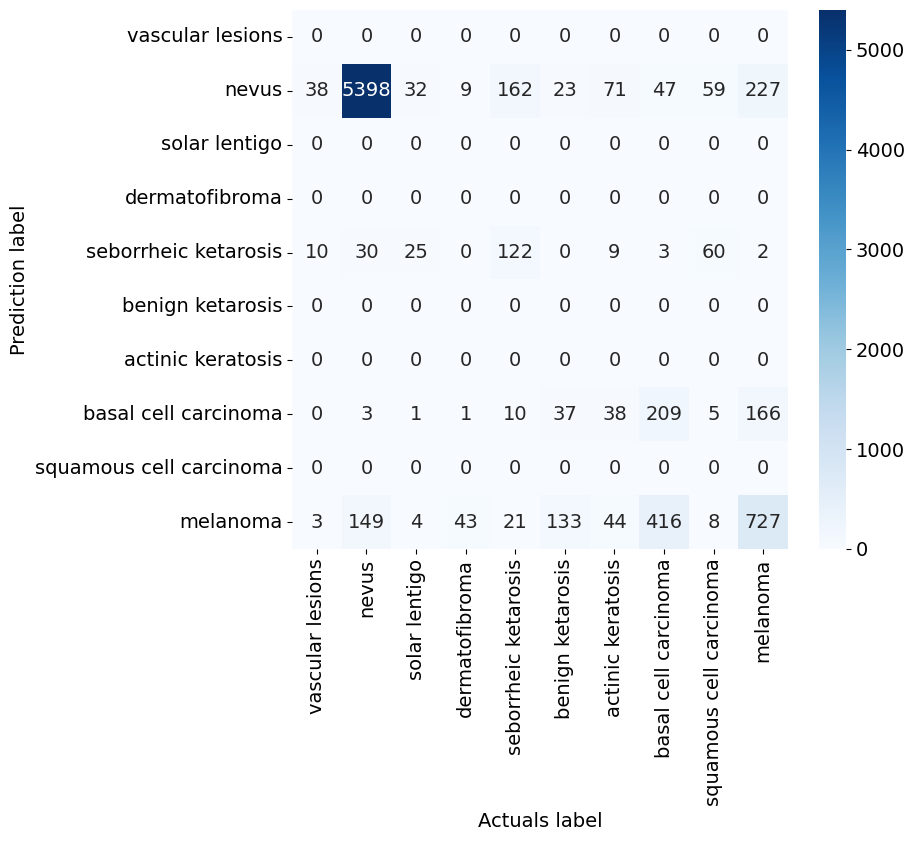

____________________________________________________________
Accuracy score: 77.36
Sensitivity: 0.7736
Specificity: 0.9748
Matthews corrcoef: 0.5385
F1: 0.7736
NPV: 0.9748
PPV: 0.7736
FNR: 0.2264
FPR: 0.0252
____________________________________________________________
Recall micro: 0.7736
Recall macro: 0.2312
Precision micro: 0.7736
Precision macro: 0.2272
F1 score micro: 0.7736
F1 score macro: 0.2260
Jaccard score micro: 0.6308
Jaccard score macro: 0.1730
Specificity macro: 0.9593
Specificity weighted: 0.8198
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.7584
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9827
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 1.0000
Specificity none - class basal cell carcinoma (7): 0.9660
Specificity none - class squamous cell carcinoma (8): 1.000

C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [33]:
actuals = []
predictions = []

test_NN(NET_light_256_128_64, testloader)

#torch.save(actuals, 'NET_light_256_128_64\\actuals.pt')
#torch.save(predictions, 'NET_light_256_128_64\\predictions.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

#torch.save(matrix, 'NET_light_256_128_64\\matrix.pt')

test_metric()

____________________________________________________________
Время тестирования: 00:00:06
Время тестирования в секундах: 6.266299



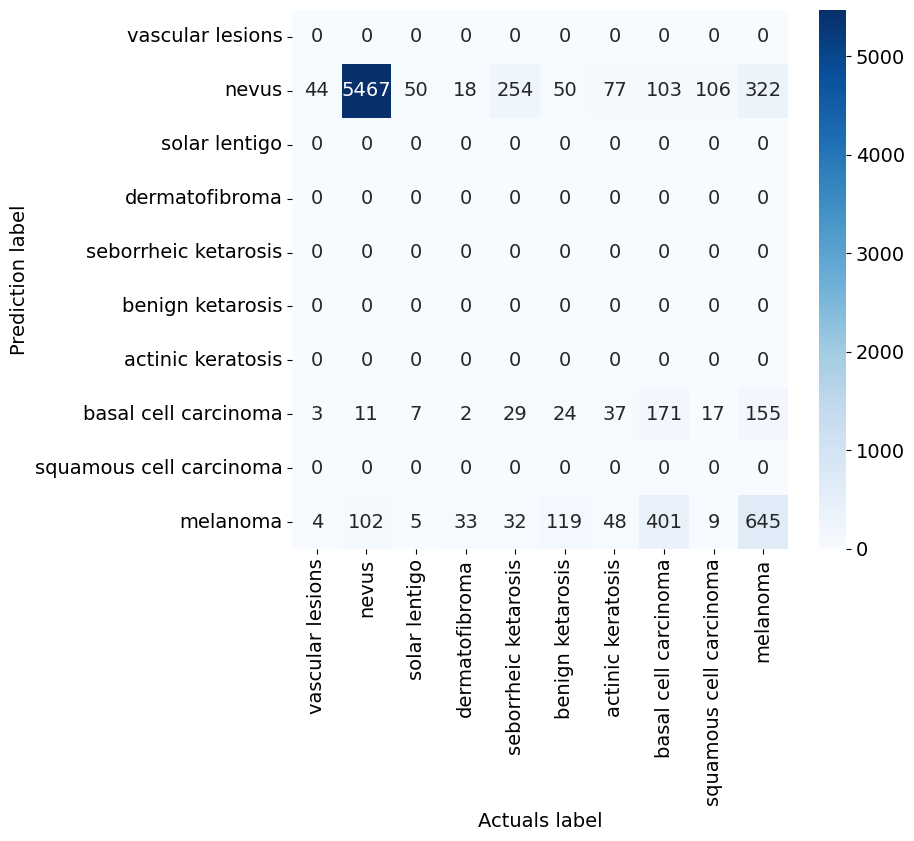

____________________________________________________________
Accuracy score: 75.29
Sensitivity: 0.7529
Specificity: 0.9725
Matthews corrcoef: 0.4707
F1: 0.7529
NPV: 0.9725
PPV: 0.7529
FNR: 0.2471
FPR: 0.0275
____________________________________________________________
Recall micro: 0.7529
Recall macro: 0.1808
Precision micro: 0.7529
Precision macro: 0.1679
F1 score micro: 0.7529
F1 score macro: 0.1720
Jaccard score micro: 0.6037
Jaccard score macro: 0.1350
Specificity macro: 0.9488
Specificity weighted: 0.7353
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.6297
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 1.0000
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 1.0000
Specificity none - class basal cell carcinoma (7): 0.9628
Specificity none - class squamous cell carcinoma (8): 1.000

C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [35]:
actuals = []
predictions = []

test_NN(NET_light_64, testloader)

#torch.save(actuals, 'NET_light_64\\actuals.pt')
#torch.save(predictions, 'NET_light_64\\predictions.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

#torch.save(matrix, 'NET_light_64\\matrix.pt')

test_metric()

____________________________________________________________
Время тестирования: 00:00:09
Время тестирования в секундах: 9.868897



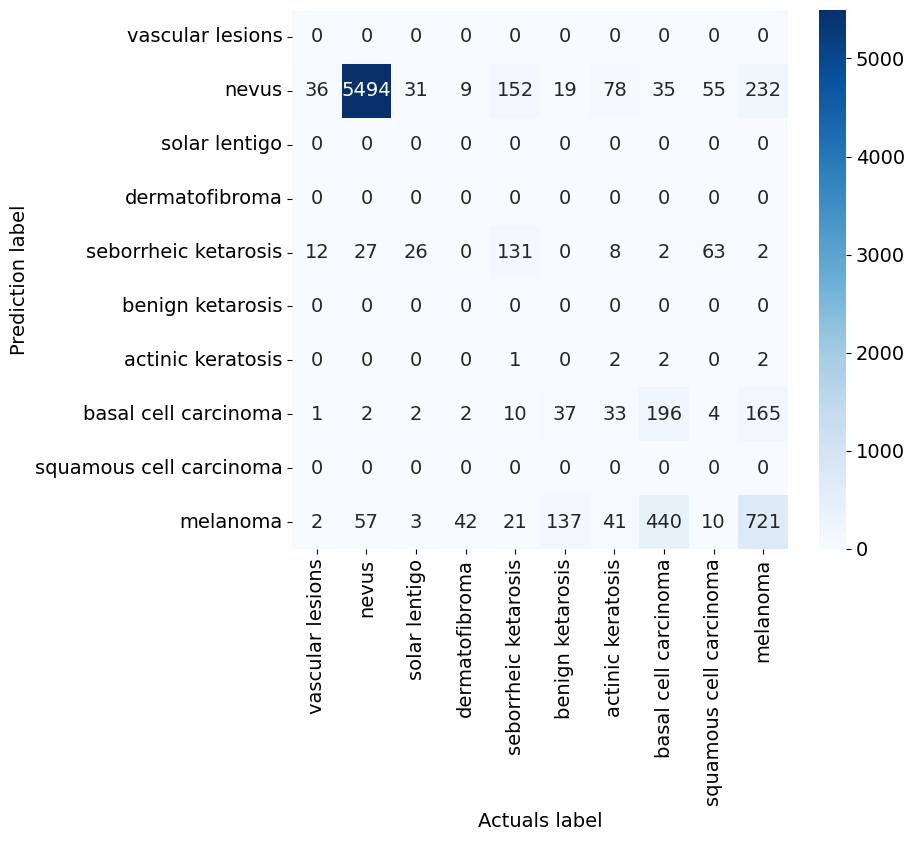

____________________________________________________________
Accuracy score: 78.42
Sensitivity: 0.7842
Specificity: 0.9760
Matthews corrcoef: 0.5571
F1: 0.7842
NPV: 0.9760
PPV: 0.7842
FNR: 0.2158
FPR: 0.0240
____________________________________________________________
Recall micro: 0.7842
Recall macro: 0.2346
Precision micro: 0.7842
Precision macro: 0.2587
F1 score micro: 0.7842
F1 score macro: 0.2312
Jaccard score micro: 0.6450
Jaccard score macro: 0.1777
Specificity macro: 0.9610
Specificity weighted: 0.8261
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.7660
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9826
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 0.9994
Specificity none - class basal cell carcinoma (7): 0.9666
Specificity none - class squamous cell carcinoma (8): 1.000

C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [37]:
actuals = []
predictions = []

test_NN(NET_light_NACH, testloader)

#torch.save(actuals, 'NET_light_NACH\\actuals.pt')
#torch.save(predictions, 'NET_light_NACH\\predictions.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

#torch.save(matrix, 'NET_light_NACH\\matrix.pt')

test_metric()

In [38]:
test_1 = test(NET_light_NACH, testloader, device)
print(f"Точность изначальной модели: {test_1:.2f}%")

test_2 = test(NET_light_64_32_16, testloader, device)
print(f"Точность модели 64_32_16: {test_2:.2f}%")

test_3 = test(NET_light_16, testloader, device)
print(f"Точность модели 16: {test_3:.2f}%")

test_4 = test(NET_light_128_64_32, testloader, device)
print(f"Точность модели 128_64_32: {test_4:.2f}%")

test_5 = test(NET_light_32, testloader, device)
print(f"Точность модели 32: {test_5:.2f}%")

test_6 = test(NET_light_256_128_64, testloader, device)
print(f"Точность модели 256_128_64: {test_6:.2f}%")

test_7 = test(NET_light_64, testloader, device)
print(f"Точность модели 64: {test_7:.2f}%")

____________________________________________________________
       Время выхода с сети: 00:00:00
       Время выхода с сети в секундах: 0.131161
____________________________________________________________
Время тестирования: 00:00:09
Время тестирования в секундах: 9.948715

Точность изначальной модели: 78.42%
____________________________________________________________
       Время выхода с сети: 00:00:00
       Время выхода с сети в секундах: 0.203884
____________________________________________________________
Время тестирования: 00:00:05
Время тестирования в секундах: 5.828984

Точность модели 64_32_16: 76.15%
____________________________________________________________
       Время выхода с сети: 00:00:00
       Время выхода с сети в секундах: 0.121830
____________________________________________________________
Время тестирования: 00:00:05
Время тестирования в секундах: 5.070755

Точность модели 16: 75.45%
____________________________________________________________
       Время